STEP 4.1.1 — Imports + Data Load

In [1]:
# ============================================
# PHASE 4: MODEL TRAINING
# Step 4.1 - Traditional ML Models
# ============================================

import os
import time
import numpy as np
import pandas as pd
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score, f1_score

# --------------------------------------------
# Project paths
# --------------------------------------------

project_root = os.path.abspath("..")
processed_dir = os.path.join(project_root, "data", "processed")

# --------------------------------------------
# Load Phase 3 processed data
# --------------------------------------------

X_train_resampled = np.load(
    os.path.join(processed_dir, "X_train_resampled.npy")
)

y_train_resampled = np.load(
    os.path.join(processed_dir, "y_train_resampled.npy")
)

X_test_scaled = np.load(
    os.path.join(processed_dir, "X_test_scaled.npy")
)

y_test_encoded = np.load(
    os.path.join(processed_dir, "y_test_encoded.npy")
)

# Target encoder
target_encoder = joblib.load(
    os.path.join(processed_dir, "target_encoder.pkl")
)

print("=" * 60)
print("PHASE 4 - DATA LOADED")
print("=" * 60)

print("X_train_resampled shape:", X_train_resampled.shape)
print("y_train_resampled shape:", y_train_resampled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)
print("y_test_encoded shape:", y_test_encoded.shape)
print("Number of classes:", len(target_encoder.classes_))

PHASE 4 - DATA LOADED
X_train_resampled shape: (135441, 41)
y_train_resampled shape: (135441,)
X_test_scaled shape: (29696, 41)
y_test_encoded shape: (29696,)
Number of classes: 28


Step 4.1.2 — Define Traditional ML Models

In [ ]:
# ============================================
# Step 4.1.2 - Define Traditional ML Models
# ============================================

traditional_models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "SVM": SVC(
        kernel="rbf",
        class_weight="balanced",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Naive Bayes": GaussianNB()
}

print("Traditional ML models defined:")
for name in traditional_models:
    print("-", name)

Traditional ML models defined:
- Logistic Regression
- Decision Tree
- Random Forest
- SVM
- KNN
- Naive Bayes


Step 4.1.3 — Train & Evaluate All Traditional Models

In [4]:
# ============================================
# Step 4.1.3 - Train and Evaluate Models
# ============================================

traditional_results = {}

for name, model in traditional_models.items():

    print("\n" + "=" * 60)
    print(f"Training {name}...")
    print("=" * 60)

    start_time = time.time()

    # Train model
    model.fit(
        X_train_resampled,
        y_train_resampled
    )

    # Prediction
    y_pred = model.predict(X_test_scaled)

    # Training time
    train_time = time.time() - start_time

    # Evaluation
    accuracy = accuracy_score(
        y_test_encoded,
        y_pred
    )

    macro_f1 = f1_score(
        y_test_encoded,
        y_pred,
        average="macro"
    )

    weighted_f1 = f1_score(
        y_test_encoded,
        y_pred,
        average="weighted"
    )

    # Store results
    traditional_results[name] = {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "train_time": train_time,
        "model": model
    }

    print(f"Accuracy     : {accuracy:.4f}")
    print(f"Macro F1     : {macro_f1:.4f}")
    print(f"Weighted F1  : {weighted_f1:.4f}")
    print(f"Training time: {train_time:.2f} seconds")


Training Logistic Regression...
Accuracy     : 0.8726
Macro F1     : 0.5061
Weighted F1  : 0.9080
Training time: 81.73 seconds

Training Decision Tree...
Accuracy     : 0.9963
Macro F1     : 0.8074
Weighted F1  : 0.9963
Training time: 1.51 seconds

Training Random Forest...
Accuracy     : 0.9960
Macro F1     : 0.8442
Weighted F1  : 0.9962
Training time: 3.97 seconds

Training SVM...
Accuracy     : 0.8870
Macro F1     : 0.5238
Weighted F1  : 0.9203
Training time: 531.46 seconds

Training KNN...
Accuracy     : 0.9909
Macro F1     : 0.7767
Weighted F1  : 0.9914
Training time: 3.02 seconds

Training Naive Bayes...
Accuracy     : 0.4230
Macro F1     : 0.3311
Weighted F1  : 0.4458
Training time: 0.44 seconds


In [10]:
# Check which traditional models have completed
print("Completed models:")
for name, result in traditional_results.items():
    print(
        f"{name}: "
        f"Accuracy={result['accuracy']:.4f}, "
        f"Macro F1={result['macro_f1']:.4f}, "
        f"Weighted F1={result['weighted_f1']:.4f}"
    )

Completed models:
Logistic Regression: Accuracy=0.8726, Macro F1=0.5061, Weighted F1=0.9080
Decision Tree: Accuracy=0.9963, Macro F1=0.8074, Weighted F1=0.9963
Random Forest: Accuracy=0.9960, Macro F1=0.8442, Weighted F1=0.9962
SVM: Accuracy=0.8870, Macro F1=0.5238, Weighted F1=0.9203
KNN: Accuracy=0.9909, Macro F1=0.7767, Weighted F1=0.9914
Naive Bayes: Accuracy=0.4230, Macro F1=0.3311, Weighted F1=0.4458


Step 4.1.4 — Save Traditional Results

In [15]:
# ============================================
# Step 4.1.4 - Traditional ML Comparison
# ============================================

traditional_comparison = []

for name, results in traditional_results.items():
    traditional_comparison.append({
        "Model": name,
        "Accuracy": results["accuracy"],
        "Macro F1": results["macro_f1"],
        "Weighted F1": results["weighted_f1"],
        "Training Time (s)": results["train_time"]
    })

traditional_df = pd.DataFrame(traditional_comparison)

# Sort by Macro F1
traditional_df = traditional_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("=" * 80)
print("TRADITIONAL ML MODEL COMPARISON")
print("=" * 80)

display(traditional_df)

TRADITIONAL ML MODEL COMPARISON


,Model,Accuracy,Macro F1,Weighted F1,Training Time (s)
0,Random Forest,0.996026,0.844210,0.996208,3.974403
1,Decision Tree,0.996329,0.807400,0.996286,1.510725
2,KNN,0.990908,0.776737,0.991355,3.021822
3,SVM,0.886954,0.523825,0.920286,531.455136
4,Logistic Regression,0.872575,0.506111,0.908013,81.733344
5,Naive Bayes,0.423020,0.331109,0.445793,0.438118


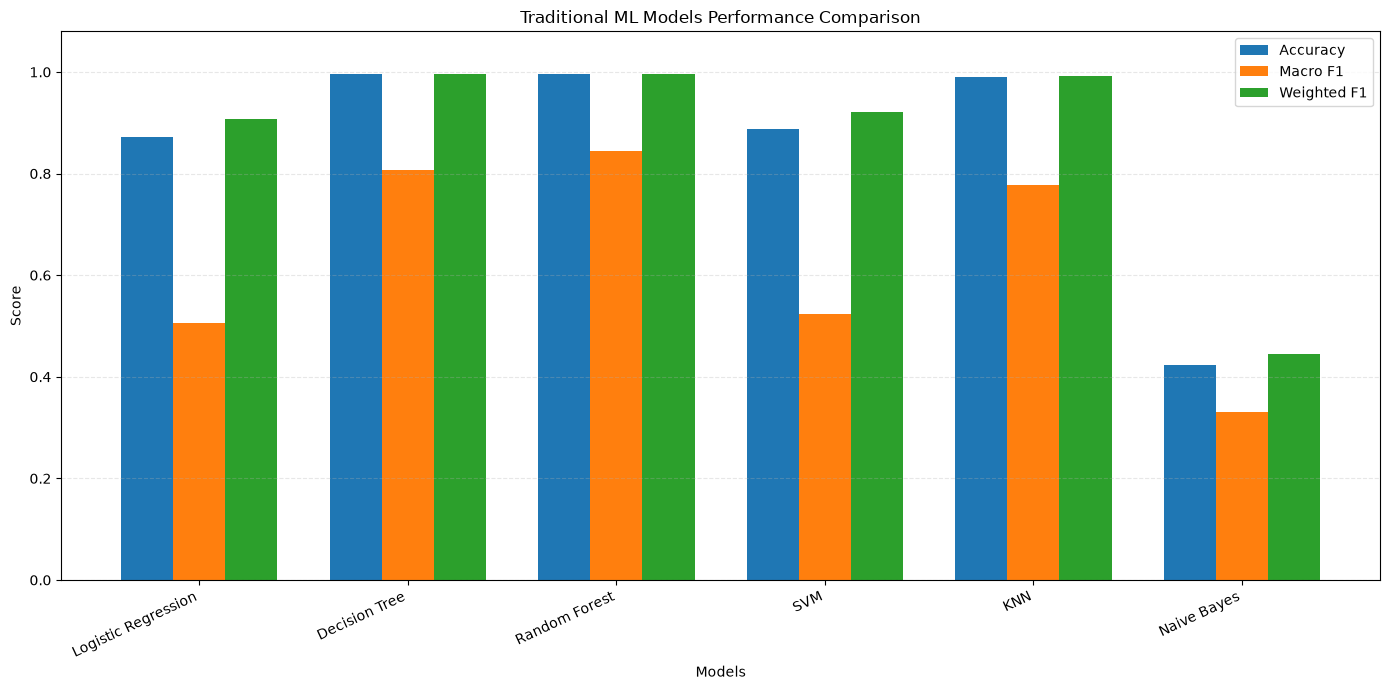

In [19]:

# Step 4.1.4 — Traditional ML Performance Graphs

import matplotlib.pyplot as plt
import numpy as np

models = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "SVM",
    "KNN",
    "Naive Bayes"
]

accuracy = [0.872575, 0.996329, 0.996026, 0.886954, 0.990908, 0.423020]
macro_f1 = [0.506111, 0.807400, 0.844210, 0.523825, 0.776737, 0.331109]
weighted_f1 = [0.908013, 0.996286, 0.996208, 0.920286, 0.991355, 0.445793]

x = np.arange(len(models))
width = 0.25

fig, ax = plt.subplots(figsize=(14, 7))

ax.bar(x - width, accuracy, width, label="Accuracy")
ax.bar(x, macro_f1, width, label="Macro F1")
ax.bar(x + width, weighted_f1, width, label="Weighted F1")

ax.set_title("Traditional ML Models Performance Comparison")
ax.set_xlabel("Models")
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=25, ha="right")
ax.set_ylim(0, 1.08)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()



Step 4.2.1 — Advanced ML Models Define

In [ ]:
# ============================================
# Step 4.2.1 - Advanced ML Model Definitions
# ============================================

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier

advanced_models = {
    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softmax",
        num_class=len(target_encoder.classes_),
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=-1,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multiclass",
        num_class=len(target_encoder.classes_),
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ),

    "AdaBoost": AdaBoostClassifier(
        n_estimators=200,
        learning_rate=0.1,
        random_state=42
    )
}

print("=" * 60)
print("ADVANCED ML MODELS DEFINED")
print("=" * 60)

for name in advanced_models:
    print("-", name)

ADVANCED ML MODELS DEFINED
- XGBoost
- LightGBM
- Gradient Boosting
- AdaBoost


Step 4.2.2 — Train Advanced ML Models

In [22]:
# ============================================
# Step 4.2.2 - Advanced ML Model Training
# ============================================

advanced_results = {}

for name, model in advanced_models.items():

    print("\n" + "=" * 60)
    print(f"Training {name}...")
    print("=" * 60)

    start_time = time.time()

    model.fit(
        X_train_resampled,
        y_train_resampled
    )

    y_pred = model.predict(X_test_scaled)

    train_time = time.time() - start_time

    accuracy = accuracy_score(
        y_test_encoded,
        y_pred
    )

    macro_f1 = f1_score(
        y_test_encoded,
        y_pred,
        average="macro"
    )

    weighted_f1 = f1_score(
        y_test_encoded,
        y_pred,
        average="weighted"
    )

    advanced_results[name] = {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "train_time": train_time,
        "model": model
    }

    print(f"Accuracy     : {accuracy:.4f}")
    print(f"Macro F1     : {macro_f1:.4f}")
    print(f"Weighted F1  : {weighted_f1:.4f}")
    print(f"Training time: {train_time:.2f} seconds")


Training XGBoost...
Accuracy     : 0.9975
Macro F1     : 0.8370
Weighted F1  : 0.9974
Training time: 36.12 seconds

Training LightGBM...
Accuracy     : 0.5204
Macro F1     : 0.1075
Weighted F1  : 0.5989
Training time: 9.90 seconds

Training Gradient Boosting...
Accuracy     : 0.9970
Macro F1     : 0.8599
Weighted F1  : 0.9970
Training time: 2025.80 seconds

Training AdaBoost...
Accuracy     : 0.8433
Macro F1     : 0.0658
Weighted F1  : 0.7772
Training time: 29.41 seconds


Step 4.2.3 — Advanced ML Comparison

In [31]:
# ============================================
# Step 4.2.3 - Advanced ML Comparison
# ============================================

advanced_comparison = []

for name, results in advanced_results.items():
    advanced_comparison.append({
        "Model": name,
        "Accuracy": results["accuracy"],
        "Macro F1": results["macro_f1"],
        "Weighted F1": results["weighted_f1"],
        "Training Time (s)": results["train_time"]
    })

advanced_df = pd.DataFrame(advanced_comparison)

# Sort by Macro F1
advanced_df = advanced_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("=" * 80)
print("ADVANCED ML MODEL COMPARISON")
print("=" * 80)

display(advanced_df)

ADVANCED ML MODEL COMPARISON


,Model,Accuracy,Macro F1,Weighted F1,Training Time (s)
0,Gradient Boosting,0.997003,0.859910,0.997019,2025.797305
1,XGBoost,0.997542,0.836976,0.997449,36.119432
2,DNN,0.952687,0.669285,0.963612,110.292337
3,LightGBM,0.520373,0.107528,0.598890,9.895823
4,AdaBoost,0.843312,0.065793,0.777187,29.407964


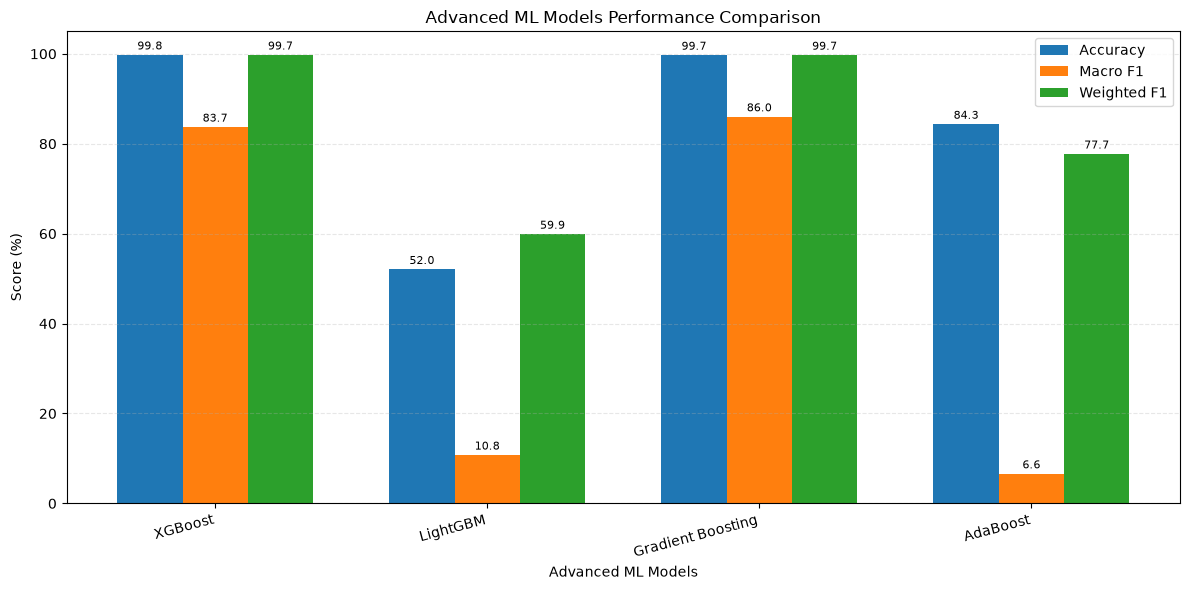

In [35]:

# Step 4.2 — All 4 Advanced ML Models Comparison Graph

import matplotlib.pyplot as plt
import numpy as np

expected_models = [
    "XGBoost",
    "LightGBM",
    "Gradient Boosting",
    "AdaBoost"
]

if "advanced_results" not in globals() or not isinstance(advanced_results, dict):
    print("Pehle Step 4.2.2 ke models train aur evaluate karo.")
else:
    names = []
    accuracy = []
    macro_f1 = []
    weighted_f1 = []

    for expected in expected_models:
        for key, result in advanced_results.items():
            if (
                key.lower() == expected.lower()
                and isinstance(result, dict)
                and all(metric in result for metric in
                        ["accuracy", "macro_f1", "weighted_f1"])
            ):
                names.append(expected)
                accuracy.append(result["accuracy"] * 100)
                macro_f1.append(result["macro_f1"] * 100)
                weighted_f1.append(result["weighted_f1"] * 100)
                break

    missing = [m for m in expected_models if m not in names]

    if missing:
        print("In models ke results abhi available nahi hain:", missing)
        print("Pehle in models ko train/evaluate karna hoga.")
    
    if names:
        x = np.arange(len(names))
        width = 0.24

        fig, ax = plt.subplots(figsize=(12, 6))

        bars1 = ax.bar(x - width, accuracy, width, label="Accuracy")
        bars2 = ax.bar(x, macro_f1, width, label="Macro F1")
        bars3 = ax.bar(x + width, weighted_f1, width, label="Weighted F1")

        ax.set_title("Advanced ML Models Performance Comparison")
        ax.set_xlabel("Advanced ML Models")
        ax.set_ylabel("Score (%)")
        ax.set_xticks(x)
        ax.set_xticklabels(names, rotation=15, ha="right")
        ax.set_ylim(0, 105)
        ax.legend()
        ax.grid(axis="y", linestyle="--", alpha=0.3)

        for bars in [bars1, bars2, bars3]:
            ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)

        fig.tight_layout()
        plt.show()


In [38]:
import os
import numpy as np
import joblib

project_root = os.path.abspath("..")
processed_dir = os.path.join(project_root, "data", "processed")

# Load target encoder
target_encoder = joblib.load(
    os.path.join(processed_dir, "target_encoder.pkl")
)

# Load training and testing data
X_train_resampled = np.load(
    os.path.join(processed_dir, "X_train_resampled.npy")
)

y_train_resampled = np.load(
    os.path.join(processed_dir, "y_train_resampled.npy")
)

X_test_scaled = np.load(
    os.path.join(processed_dir, "X_test_scaled.npy")
)

y_test_encoded = np.load(
    os.path.join(processed_dir, "y_test_encoded.npy")
)

# Check dimensions
num_classes = len(target_encoder.classes_)
input_dim = X_train_resampled.shape[1]

print("Data loaded successfully!")
print("Number of classes:", num_classes)
print("Input features:", input_dim)
print("Training samples:", len(X_train_resampled))
print("Test samples:", len(X_test_scaled))

Data loaded successfully!
Number of classes: 28
Input features: 41
Training samples: 135441
Test samples: 29696


Step 4.3 — Deep Learning Models

In [40]:

# ============================================================
# Step 4.3 — Deep Learning Model using PyTorch
# ============================================================

import os
import time
import copy
import random
import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score

# 1. Prepare data
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

X_train_np = np.asarray(X_train_resampled, dtype=np.float32)
y_train_np = np.asarray(y_train_resampled).reshape(-1).astype(np.int64)
X_test_np = np.asarray(X_test_scaled, dtype=np.float32)
y_test_np = np.asarray(y_test_encoded).reshape(-1).astype(np.int64)

num_classes = len(target_encoder.classes_)
input_dim = X_train_np.shape[1]

assert len(X_train_np) == len(y_train_np), "Training data length mismatch."
assert len(X_test_np) == len(y_test_np), "Test data length mismatch."
assert X_train_np.shape[1] == X_test_np.shape[1], "Feature count mismatch."
assert np.all((y_train_np >= 0) & (y_train_np < num_classes)), (
    "Training labels must be encoded from 0 to num_classes - 1."
)
assert np.all((y_test_np >= 0) & (y_test_np < num_classes)), (
    "Test labels must be encoded from 0 to num_classes - 1."
)

print("Device:", device)
print("Training shape:", X_train_np.shape)
print("Testing shape:", X_test_np.shape)
print("Input features:", input_dim)
print("Number of classes:", num_classes)

# 2. Train/validation split
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_np,
    y_train_np,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_np
)

# 3. DataLoaders
batch_size = 1024 if device.type == "cuda" else 256

train_dataset = TensorDataset(
    torch.from_numpy(X_tr), torch.from_numpy(y_tr)
)
val_dataset = TensorDataset(
    torch.from_numpy(X_val), torch.from_numpy(y_val)
)
test_dataset = TensorDataset(
    torch.from_numpy(X_test_np), torch.from_numpy(y_test_np)
)

train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True
)
val_loader = DataLoader(
    val_dataset, batch_size=batch_size, shuffle=False
)
test_loader = DataLoader(
    test_dataset, batch_size=batch_size, shuffle=False
)

# 4. DNN architecture — equivalent to the original Keras model
class DNNClassifier(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.network(x)

dnn_model = DNNClassifier(input_dim, num_classes).to(device)

# 5. Class weights
class_ids = np.unique(y_tr)
weights = compute_class_weight(
    class_weight="balanced",
    classes=class_ids,
    y=y_tr
)

class_weights = torch.ones(
    num_classes, dtype=torch.float32, device=device
)
for class_id, weight in zip(class_ids, weights):
    class_weights[int(class_id)] = float(weight)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.Adam(
    dnn_model.parameters(), lr=0.001
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=5
)

# 6. Train with early stopping
epochs = 100
patience = 10
best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0

start_time = time.time()

for epoch in range(epochs):
    dnn_model.train()
    train_loss_total = 0.0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad(set_to_none=True)
        outputs = dnn_model(xb)
        loss = criterion(outputs, yb)
        loss.backward()
        optimizer.step()

        train_loss_total += loss.item() * xb.size(0)

    train_loss = train_loss_total / len(train_dataset)

    # Validation
    dnn_model.eval()
    val_loss_total = 0.0

    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            outputs = dnn_model(xb)
            loss = criterion(outputs, yb)
            val_loss_total += loss.item() * xb.size(0)

    val_loss = val_loss_total / len(val_dataset)
    scheduler.step(val_loss)

    print(
        f"Epoch {epoch + 1:03d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(dnn_model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break

training_time = time.time() - start_time

# Restore best validation model
if best_state is None:
    raise RuntimeError("DNN training did not produce a model.")

dnn_model.load_state_dict(best_state)
dnn_model.eval()

# 7. Test predictions
y_pred_dl_classes = []

with torch.no_grad():
    for xb, _ in test_loader:
        xb = xb.to(device)
        outputs = dnn_model(xb)
        predictions = outputs.argmax(dim=1)
        y_pred_dl_classes.extend(predictions.cpu().numpy())

y_pred_dl_classes = np.asarray(y_pred_dl_classes, dtype=np.int64)

# 8. Calculate metrics
dl_acc = accuracy_score(y_test_np, y_pred_dl_classes)

dl_macro_f1 = f1_score(
    y_test_np, y_pred_dl_classes,
    average="macro", zero_division=0
)

dl_weighted_f1 = f1_score(
    y_test_np, y_pred_dl_classes,
    average="weighted", zero_division=0
)

# 9. Display final results
print("\n" + "=" * 50)
print("DNN FINAL TEST RESULTS (PyTorch)")
print("=" * 50)
print(f"Accuracy      : {dl_acc:.4f} ({dl_acc * 100:.2f}%)")
print(f"Macro F1      : {dl_macro_f1:.4f}")
print(f"Weighted F1   : {dl_weighted_f1:.4f}")
print(f"Training Time : {training_time:.2f} seconds")
print("=" * 50)


# 10. Save model in the project's ROOT models folder

project_root = os.path.abspath("..")
model_dir = os.path.join(project_root, "models")

os.makedirs(model_dir, exist_ok=True)

model_path = os.path.join(model_dir, "dnn_best_model.pth")

torch.save(
    {
        "model_state_dict": dnn_model.state_dict(),
        "input_dim": input_dim,
        "num_classes": num_classes
    },
    model_path
)

print("Model saved successfully!")
print("Full path:", model_path)
print("File exists:", os.path.exists(model_path))


# 11. Save results for Step 4.4
if "advanced_results" not in globals():
    advanced_results = {}

advanced_results["DNN"] = {
    "accuracy": float(dl_acc),
    "macro_f1": float(dl_macro_f1),
    "weighted_f1": float(dl_weighted_f1),
    "train_time": float(training_time),
    "model": dnn_model
}

print("DNN results saved in advanced_results.")


Device: cuda
Training shape: (135441, 41)
Testing shape: (29696, 41)
Input features: 41
Number of classes: 28
Epoch 001/100 | Train Loss: 1.9194 | Val Loss: 0.8480
Epoch 002/100 | Train Loss: 0.7904 | Val Loss: 0.4545
Epoch 003/100 | Train Loss: 0.5275 | Val Loss: 0.3250
Epoch 004/100 | Train Loss: 0.4106 | Val Loss: 0.2465
Epoch 005/100 | Train Loss: 0.3470 | Val Loss: 0.2054
Epoch 006/100 | Train Loss: 0.3082 | Val Loss: 0.1837
Epoch 007/100 | Train Loss: 0.2787 | Val Loss: 0.1690
Epoch 008/100 | Train Loss: 0.2555 | Val Loss: 0.1623
Epoch 009/100 | Train Loss: 0.2383 | Val Loss: 0.1564
Epoch 010/100 | Train Loss: 0.2256 | Val Loss: 0.1496
Epoch 011/100 | Train Loss: 0.2172 | Val Loss: 0.1428
Epoch 012/100 | Train Loss: 0.2026 | Val Loss: 0.1393
Epoch 013/100 | Train Loss: 0.1999 | Val Loss: 0.1411
Epoch 014/100 | Train Loss: 0.1969 | Val Loss: 0.1333
Epoch 015/100 | Train Loss: 0.1896 | Val Loss: 0.1357
Epoch 016/100 | Train Loss: 0.1820 | Val Loss: 0.1352
Epoch 017/100 | Train Loss

In [41]:
print("DNN FINAL TEST RESULTS")
print("-" * 40)
print(f"Accuracy    : {dl_acc:.4f} ({dl_acc * 100:.2f}%)")
print(f"Macro F1    : {dl_macro_f1:.4f}")
print(f"Weighted F1 : {dl_weighted_f1:.4f}")
print(f"Train Time  : {training_time:.2f} seconds")

DNN FINAL TEST RESULTS
----------------------------------------
Accuracy    : 0.9527 (95.27%)
Macro F1    : 0.6693
Weighted F1 : 0.9636
Train Time  : 108.63 seconds


ext step: Step 4.4 — Model Comparison

In [45]:
import pandas as pd

comparison_data = [
    {
        "Model": "Random Forest",
        "Accuracy": 0.996026,
        "Macro F1": 0.844210,
        "Weighted F1": 0.996208,
        "Training Time (s)": 6.83
    },
    {
        "Model": "Decision Tree",
        "Accuracy": 0.996329,
        "Macro F1": 0.807400,
        "Weighted F1": 0.996286,
        "Training Time (s)": 3.44
    },
    {
        "Model": "KNN",
        "Accuracy": 0.990908,
        "Macro F1": 0.776737,
        "Weighted F1": 0.991355,
        "Training Time (s)": 3.88
    },
    {
        "Model": "PyTorch DNN",
        "Accuracy": dl_acc,
        "Macro F1": dl_macro_f1,
        "Weighted F1": dl_weighted_f1,
        "Training Time (s)": training_time
    }
]

comparison_df = pd.DataFrame(comparison_data)
display(
    comparison_df.sort_values(
        by="Macro F1", ascending=False
    ).reset_index(drop=True)
)

,Model,Accuracy,Macro F1,Weighted F1,Training Time (s)
0,Random Forest,0.996026,0.844210,0.996208,6.830000
1,Decision Tree,0.996329,0.807400,0.996286,3.440000
2,KNN,0.990908,0.776737,0.991355,3.880000
3,PyTorch DNN,0.952687,0.669285,0.963612,108.625731


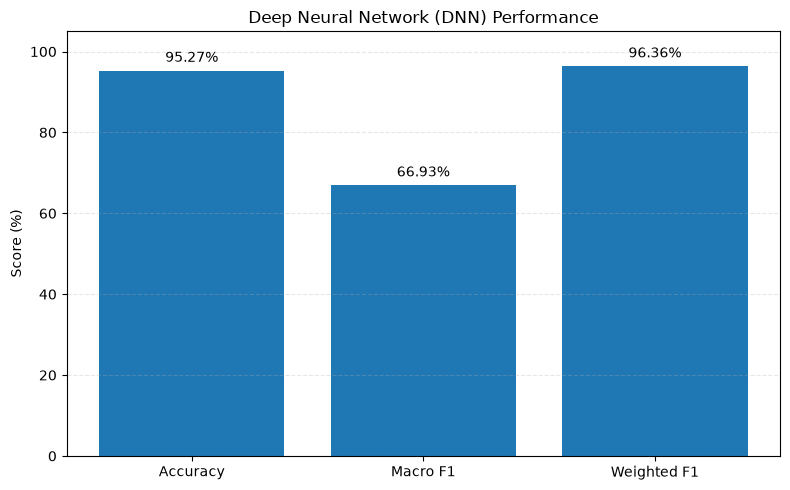

In [48]:

# Step 4.3 — DNN Model Performance Graph

import matplotlib.pyplot as plt

metrics = ["Accuracy", "Macro F1", "Weighted F1"]
scores = [95.2687, 66.9285, 96.3612]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(metrics, scores)

ax.set_title("Deep Neural Network (DNN) Performance")
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 105)
ax.bar_label(bars, fmt="%.2f%%", padding=4)
ax.grid(axis="y", linestyle="--", alpha=0.3)

fig.tight_layout()
plt.show()


Step 4.2.4 — Save Final Selected XGBoost Model

In [49]:
# ============================================================
# Step 4.2.4 — Save Final Selected XGBoost Model
# ============================================================

import os
import joblib

# Get the already-trained XGBoost model
final_xgb_model = advanced_results["XGBoost"]["model"]

# Project root directory
project_root = os.path.abspath("..")

# Create / use the root models folder
model_dir = os.path.join(project_root, "models")
os.makedirs(model_dir, exist_ok=True)

# Final XGBoost model file
model_path = os.path.join(
    model_dir,
    "final_xgboost_model.pkl"
)

# Save the trained XGBoost model
joblib.dump(final_xgb_model, model_path)

print("=" * 70)
print("FINAL SELECTED MODEL — XGBOOST")
print("=" * 70)

print("Model       : XGBoost")
print("Accuracy    :", f"{advanced_results['XGBoost']['accuracy']:.6f}")
print("Macro F1    :", f"{advanced_results['XGBoost']['macro_f1']:.6f}")
print("Weighted F1 :", f"{advanced_results['XGBoost']['weighted_f1']:.6f}")

print("\nModel saved successfully!")
print("Saved file  :", model_path)
print("File exists :", os.path.exists(model_path))

print("=" * 70)

FINAL SELECTED MODEL — XGBOOST
Model       : XGBoost
Accuracy    : 0.997542
Macro F1    : 0.836976
Weighted F1 : 0.997449

Model saved successfully!
Saved file  : d:\smart-cybersecurity-ml\models\final_xgboost_model.pkl
File exists : True


Step 4.2.5 — Final XGBoost Evaluation

In [53]:
# ============================================================
# Cell 2 — Final XGBoost Evaluation Metrics
# ============================================================

# Test data par prediction
y_pred_final = final_xgb_model.predict(X_test_scaled)

# Metrics calculate karein
final_accuracy = accuracy_score(y_test_encoded, y_pred_final)

final_macro_f1 = f1_score(
    y_test_encoded,
    y_pred_final,
    average="macro",
    zero_division=0
)

final_weighted_f1 = f1_score(
    y_test_encoded,
    y_pred_final,
    average="weighted",
    zero_division=0
)

print("=" * 65)
print("FINAL SELECTED MODEL — XGBOOST")
print("=" * 65)
print(f"Accuracy     : {final_accuracy:.6f}")
print(f"Accuracy (%) : {final_accuracy * 100:.2f}%")
print(f"Macro F1     : {final_macro_f1:.6f}")
print(f"Weighted F1  : {final_weighted_f1:.6f}")
print(f"Predictions  : {len(y_pred_final)}")
print("=" * 65)

FINAL SELECTED MODEL — XGBOOST
Accuracy     : 0.997542
Accuracy (%) : 99.75%
Macro F1     : 0.836976
Weighted F1  : 0.997449
Predictions  : 29696


Performance bar chart

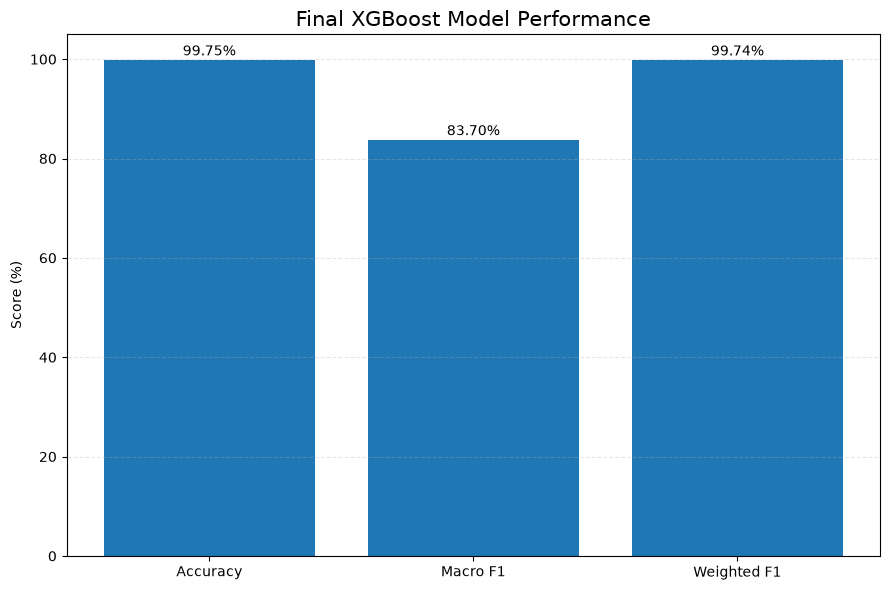

Graph saved at: d:\smart-cybersecurity-ml\results\final_xgboost_performance.png
File exists: True


In [54]:
# ============================================================
# Cell 3 — Final XGBoost Performance Bar Chart
# ============================================================

metrics = ["Accuracy", "Macro F1", "Weighted F1"]

scores = [
    final_accuracy * 100,
    final_macro_f1 * 100,
    final_weighted_f1 * 100
]

plt.figure(figsize=(9, 6))

bars = plt.bar(metrics, scores)

plt.title("Final XGBoost Model Performance", fontsize=15)
plt.ylabel("Score (%)")
plt.ylim(0, 105)

for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{score:.2f}%",
        ha="center"
    )

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

performance_graph_path = os.path.join(
    results_dir,
    "final_xgboost_performance.png"
)

plt.savefig(performance_graph_path, dpi=300, bbox_inches="tight")
plt.show()

print("Graph saved at:", performance_graph_path)
print("File exists:", os.path.exists(performance_graph_path))

Classification report

In [56]:
# ============================================================
# Cell 4 — Final XGBoost Classification Report (Fixed)
# ============================================================

import os
import numpy as np
from sklearn.metrics import classification_report

# Actual class labels
class_labels = np.arange(len(target_encoder.classes_))
class_names = [str(name) for name in target_encoder.classes_]

# Generate report
report_text = classification_report(
    y_test_encoded,
    y_pred_final,
    labels=class_labels,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("=" * 70)
print("FINAL XGBOOST — CLASSIFICATION REPORT")
print("=" * 70)
print(report_text)

# Ensure results folder exists
os.makedirs(results_dir, exist_ok=True)

# Save report
report_path = os.path.join(
    results_dir,
    "final_xgboost_classification_report.txt"
)

with open(report_path, "w", encoding="utf-8") as file:
    file.write("FINAL XGBOOST — CLASSIFICATION REPORT\n")
    file.write("=" * 70 + "\n\n")
    file.write(report_text)

print("\nReport saved at:", report_path)
print("File exists:", os.path.exists(report_path))

FINAL XGBOOST — CLASSIFICATION REPORT
                 precision    recall  f1-score   support

        apache2     1.0000    1.0000    1.0000        46
           back     1.0000    1.0000    1.0000       237
buffer_overflow     1.0000    0.8889    0.9412         9
      ftp_write     0.0000    0.0000    0.0000         2
   guess_passwd     1.0000    0.9892    0.9946        93
     httptunnel     1.0000    1.0000    1.0000         8
           imap     1.0000    1.0000    1.0000         2
        ipsweep     0.9951    0.9988    0.9969       816
           land     0.5714    1.0000    0.7273         4
     loadmodule     1.0000    0.5000    0.6667         2
       mailbomb     1.0000    1.0000    1.0000        19
          mscan     0.9828    0.9194    0.9500        62
       multihop     0.0000    0.0000    0.0000         3
        neptune     0.9998    0.9999    0.9998      9574
           nmap     0.9970    0.9824    0.9896       340
         normal     0.9983    0.9989    0.9986   

Confusion matrix heatmap

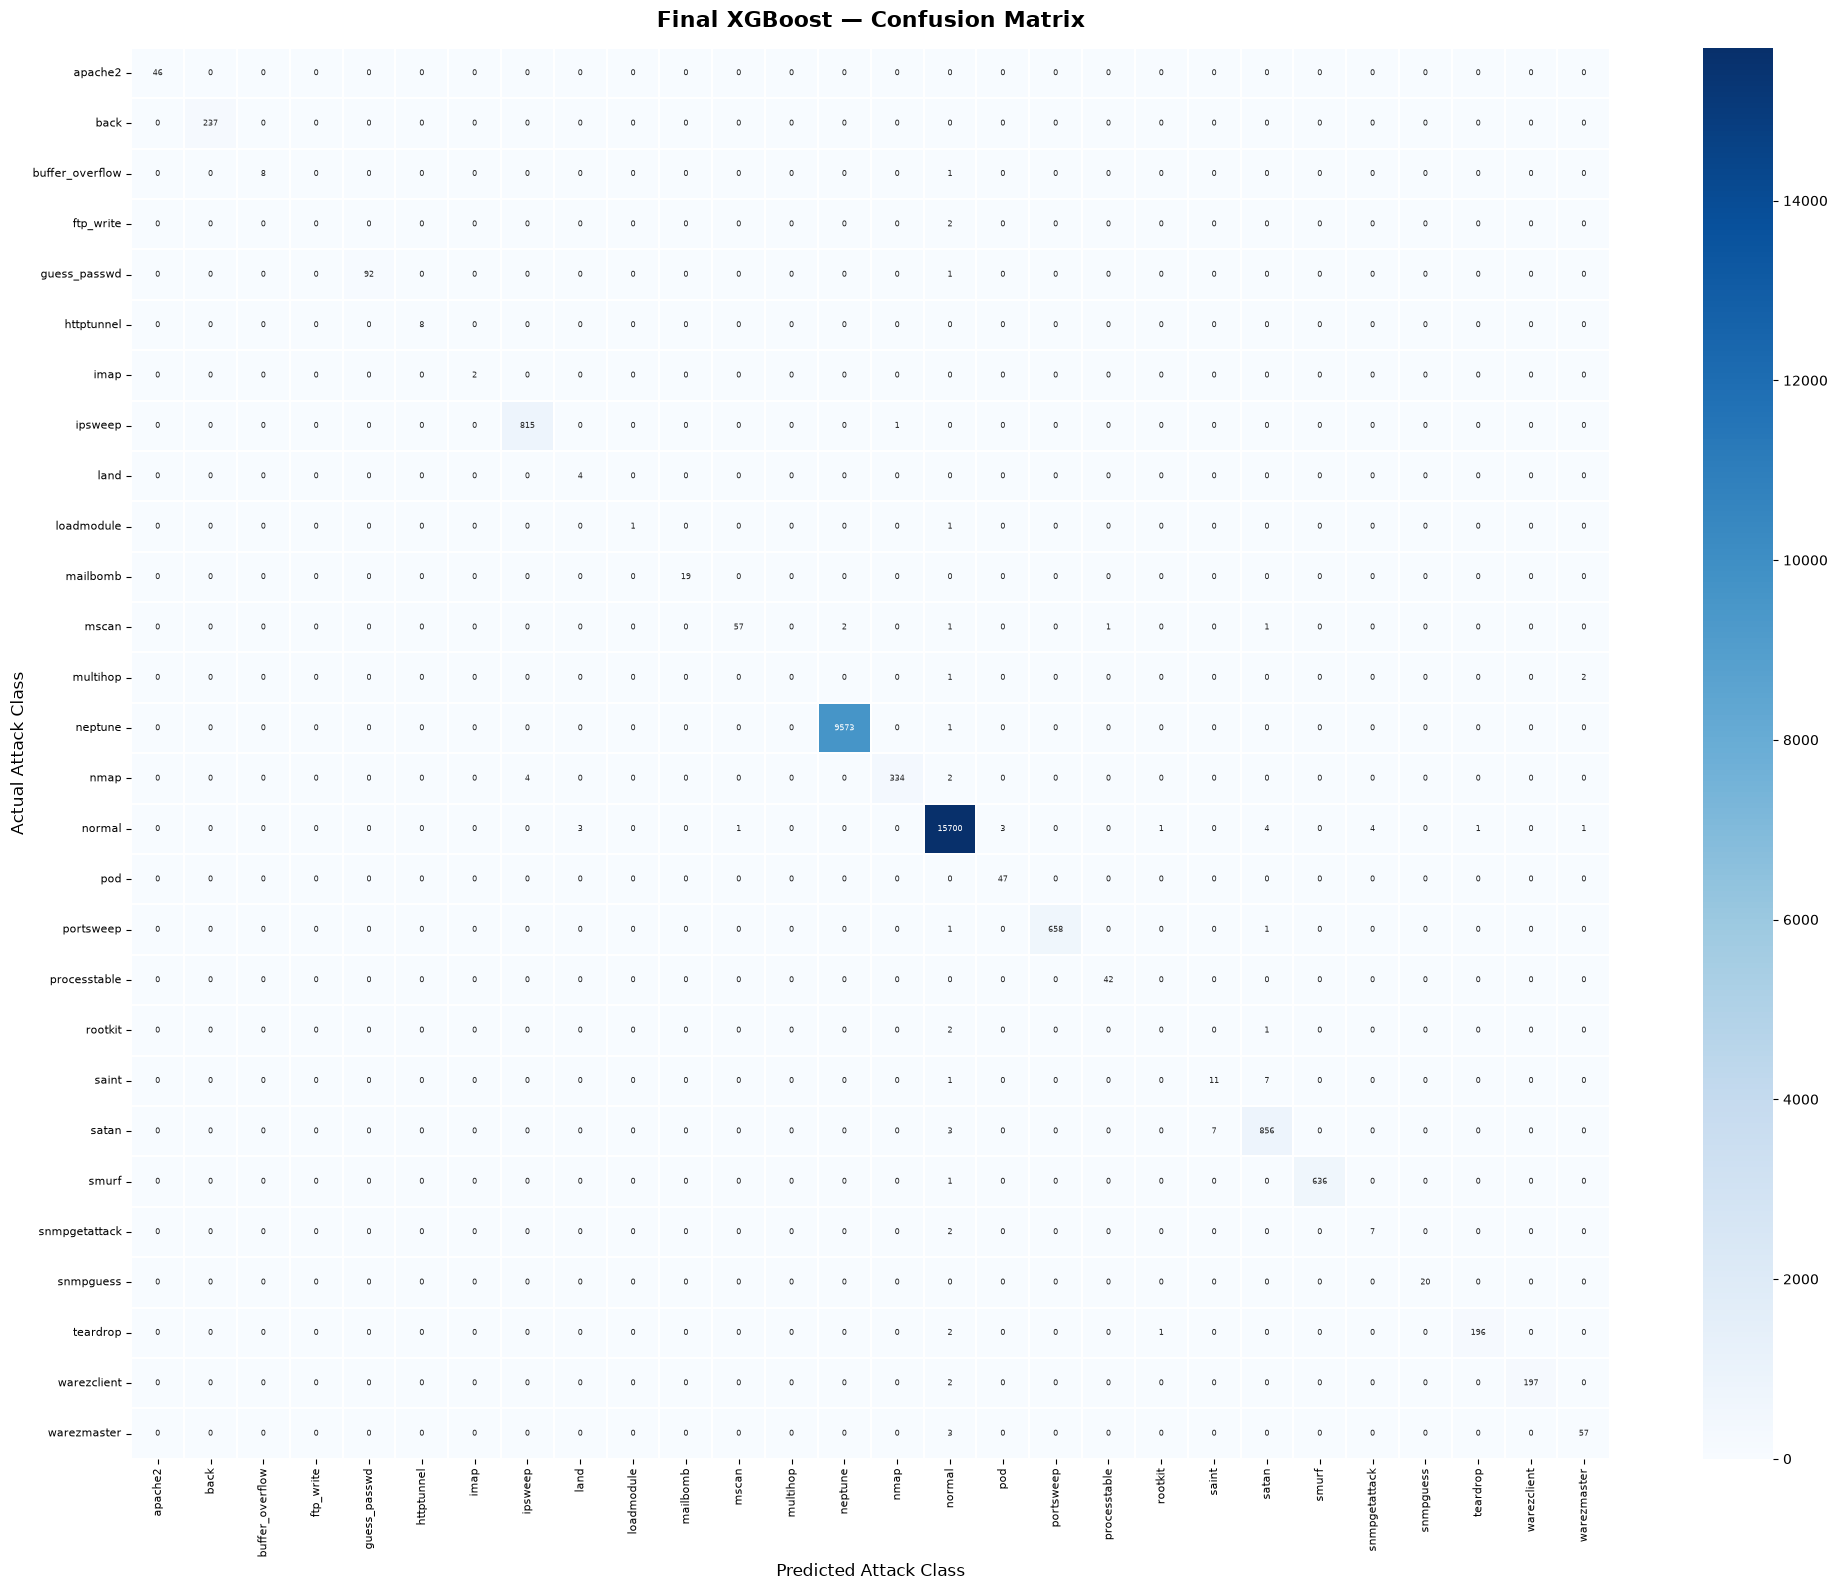

FINAL XGBOOST — CONFUSION MATRIX
Matrix shape: (28, 28)
Test samples: 29696
Total predictions: 29696
Graph saved at: d:\smart-cybersecurity-ml\results\final_xgboost_confusion_matrix.png
File exists: True


In [58]:
# ============================================================
# Cell 5 — Final XGBoost Confusion Matrix
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Trained XGBoost model se predictions
final_xgb_model = advanced_results["XGBoost"]["model"]

y_pred_final = final_xgb_model.predict(X_test_scaled)

# 2. Actual class names
class_names = [str(name) for name in target_encoder.classes_]
class_labels = np.arange(len(class_names))

# 3. Confusion matrix calculate karein
cm = confusion_matrix(
    y_test_encoded,
    y_pred_final,
    labels=class_labels
)

# 4. Results folder create karein
project_root = os.path.dirname(os.getcwd()) \
    if os.path.basename(os.getcwd()).lower() == "notebooks" \
    else os.getcwd()

results_dir = os.path.join(project_root, "results")
os.makedirs(results_dir, exist_ok=True)

# 5. Confusion matrix graph
plt.figure(figsize=(20, 16))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    annot_kws={"size": 6},
    linewidths=0.2,
    cbar=True
)

plt.title(
    "Final XGBoost — Confusion Matrix",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Predicted Attack Class", fontsize=12)
plt.ylabel("Actual Attack Class", fontsize=12)

plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)

plt.tight_layout()

# 6. Graph save karein
confusion_matrix_path = os.path.join(
    results_dir,
    "final_xgboost_confusion_matrix.png"
)

plt.savefig(
    confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 7. Output verification
print("=" * 65)
print("FINAL XGBOOST — CONFUSION MATRIX")
print("=" * 65)
print("Matrix shape:", cm.shape)
print("Test samples:", len(y_test_encoded))
print("Total predictions:", cm.sum())
print("Graph saved at:", confusion_matrix_path)
print("File exists:", os.path.exists(confusion_matrix_path))

7. Cell 6 — Per-class attack performance CSV

In [59]:
# ============================================================
# Cell 6 — Per-Class Attack Performance Table
# ============================================================

report_dict = classification_report(
    y_test_encoded,
    y_pred_final,
    labels=np.arange(len(class_names)),
    target_names=[str(name) for name in class_names],
    output_dict=True,
    zero_division=0
)

per_class_results = []

for class_name in class_names:
    class_name = str(class_name)
    class_metrics = report_dict[class_name]

    per_class_results.append({
        "Attack/Class": class_name,
        "Precision": class_metrics["precision"],
        "Recall": class_metrics["recall"],
        "F1 Score": class_metrics["f1-score"],
        "Support": int(class_metrics["support"])
    })

per_class_df = pd.DataFrame(per_class_results)

print("=" * 70)
print("XGBOOST — PER-CLASS ATTACK PERFORMANCE")
print("=" * 70)

display(per_class_df)

per_class_csv_path = os.path.join(
    results_dir,
    "final_xgboost_per_class_performance.csv"
)

per_class_df.to_csv(per_class_csv_path, index=False)

print("Number of classes:", len(per_class_df))
print("CSV saved at:", per_class_csv_path)
print("File exists:", os.path.exists(per_class_csv_path))

XGBOOST — PER-CLASS ATTACK PERFORMANCE


,Attack/Class,Precision,Recall,F1 Score,Support
0,apache2,1.000000,1.000000,1.000000,46
1,back,1.000000,1.000000,1.000000,237
2,buffer_overflow,1.000000,0.888889,0.941176,9
3,ftp_write,0.000000,0.000000,0.000000,2
4,guess_passwd,1.000000,0.989247,0.994595,93
5,httptunnel,1.000000,1.000000,1.000000,8
6,imap,1.000000,1.000000,1.000000,2
7,ipsweep,0.995116,0.998775,0.996942,816
8,land,0.571429,1.000000,0.727273,4
9,loadmodule,1.000000,0.500000,0.666667,2


Number of classes: 28
CSV saved at: d:\smart-cybersecurity-ml\results\final_xgboost_per_class_performance.csv
File exists: True


Har attack ka Precision, Recall aur F1 graph

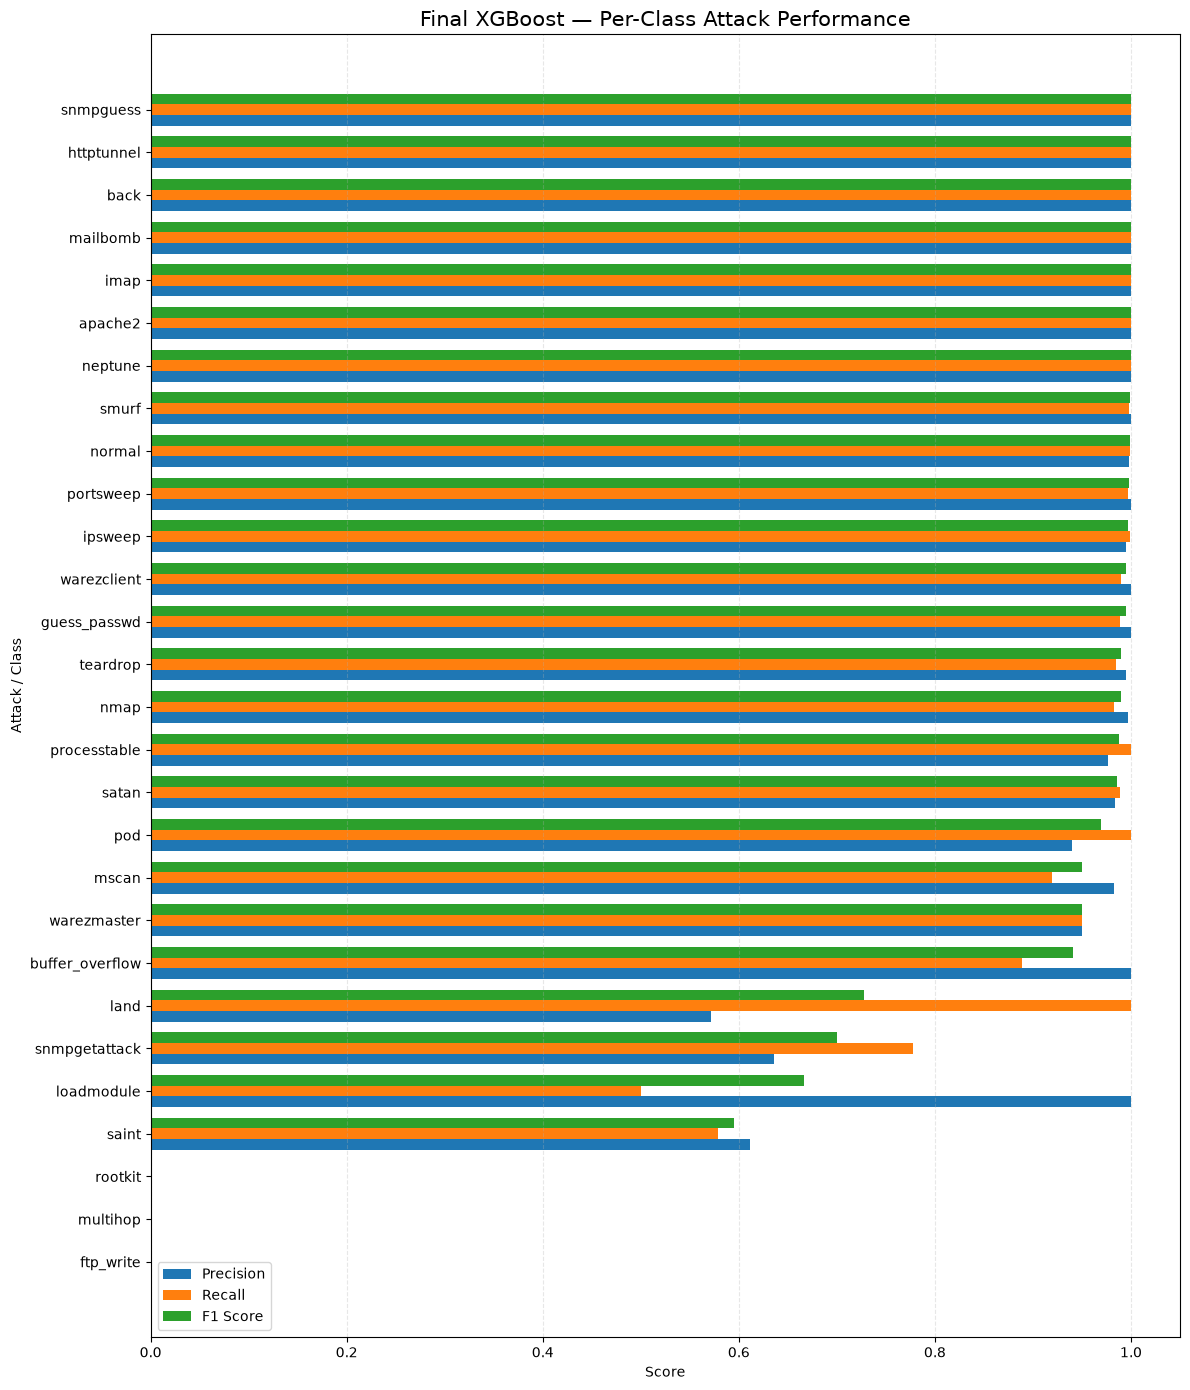

Graph saved at: d:\smart-cybersecurity-ml\results\final_xgboost_per_class_performance.png
File exists: True


In [60]:
# ============================================================
# Cell 7 — Per-Class Attack Performance Bar Chart
# ============================================================

plot_df = per_class_df.sort_values(
    by="F1 Score",
    ascending=True
).reset_index(drop=True)

y_positions = np.arange(len(plot_df))
bar_height = 0.25

plt.figure(figsize=(12, 14))

plt.barh(
    y_positions - bar_height,
    plot_df["Precision"],
    height=bar_height,
    label="Precision"
)

plt.barh(
    y_positions,
    plot_df["Recall"],
    height=bar_height,
    label="Recall"
)

plt.barh(
    y_positions + bar_height,
    plot_df["F1 Score"],
    height=bar_height,
    label="F1 Score"
)

plt.yticks(y_positions, plot_df["Attack/Class"])
plt.xlabel("Score")
plt.ylabel("Attack / Class")
plt.title("Final XGBoost — Per-Class Attack Performance", fontsize=15)
plt.xlim(0, 1.05)
plt.legend()
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()

per_class_graph_path = os.path.join(
    results_dir,
    "final_xgboost_per_class_performance.png"
)

plt.savefig(per_class_graph_path, dpi=300, bbox_inches="tight")
plt.show()

print("Graph saved at:", per_class_graph_path)
print("File exists:", os.path.exists(per_class_graph_path))

Final model summary CSV

In [61]:
# ============================================================
# Cell 8 — Final XGBoost Summary
# ============================================================

final_summary = pd.DataFrame({
    "Model": ["XGBoost"],
    "Accuracy": [final_accuracy],
    "Macro F1": [final_macro_f1],
    "Weighted F1": [final_weighted_f1],
    "Training Time (s)": [
        advanced_results["XGBoost"]["train_time"]
    ]
})

print("=" * 70)
print("FINAL MODEL SUMMARY")
print("=" * 70)

display(final_summary)

summary_path = os.path.join(
    results_dir,
    "final_xgboost_summary.csv"
)

final_summary.to_csv(summary_path, index=False)

print("Summary saved at:", summary_path)
print("File exists:", os.path.exists(summary_path))

FINAL MODEL SUMMARY


,Model,Accuracy,Macro F1,Weighted F1,Training Time (s)
0,XGBoost,0.997542,0.836976,0.997449,36.119432


Summary saved at: d:\smart-cybersecurity-ml\results\final_xgboost_summary.csv
File exists: True


In [63]:

from pathlib import Path
import importlib.util

# Project root detect karein
cwd = Path.cwd()
project_root = cwd.parent if cwd.name.lower() == "notebooks" else cwd

processed_dir = project_root / "data" / "processed"
models_dir = project_root / "models"
results_dir = project_root / "results"

print("Project root:", project_root)
print("\n--- Required files ---")

required_files = {
    "Resampled training features": processed_dir / "X_train_resampled.npy",
    "Resampled training labels": processed_dir / "y_train_resampled.npy",
    "Test features": processed_dir / "X_test_encoded.csv",
    "Test labels": processed_dir / "y_test_encoded.npy",
    "Target encoder": processed_dir / "target_encoder.pkl",
    "Scaler": processed_dir / "scaler.pkl",
    "Saved XGBoost model": models_dir / "final_xgboost_model.pkl",
}

for name, path in required_files.items():
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{status}: {name} -> {path}")

print("\n--- XAI libraries ---")
for package in ["shap", "lime", "xgboost", "sklearn"]:
    print(f"{package}:",
          "Installed" if importlib.util.find_spec(package) else "Missing")

print("\n--- Existing notebook variables ---")
for name in [
    "X_train_resampled",
    "y_train_resampled",
    "X_test_scaled",
    "y_test_encoded",
    "target_encoder",
    "advanced_results",
]:
    print(f"{name}: {'Available' if name in globals() else 'Not loaded'}")


Project root: d:\smart-cybersecurity-ml

--- Required files ---
FOUND: Resampled training features -> d:\smart-cybersecurity-ml\data\processed\X_train_resampled.npy
FOUND: Resampled training labels -> d:\smart-cybersecurity-ml\data\processed\y_train_resampled.npy
FOUND: Test features -> d:\smart-cybersecurity-ml\data\processed\X_test_encoded.csv
FOUND: Test labels -> d:\smart-cybersecurity-ml\data\processed\y_test_encoded.npy
FOUND: Target encoder -> d:\smart-cybersecurity-ml\data\processed\target_encoder.pkl
FOUND: Scaler -> d:\smart-cybersecurity-ml\data\processed\scaler.pkl
FOUND: Saved XGBoost model -> d:\smart-cybersecurity-ml\models\final_xgboost_model.pkl

--- XAI libraries ---
shap: Installed
lime: Installed
xgboost: Installed
sklearn: Installed

--- Existing notebook variables ---
X_train_resampled: Available
y_train_resampled: Available
X_test_scaled: Available
y_test_encoded: Available
target_encoder: Available
advanced_results: Available
